<a href="https://colab.research.google.com/github/zhiyuguo-innis/MSSP607/blob/main/Assignments/Copenhagen_Networks_Study_Notebook_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#SOURCE MODIFIED FROM: Team, Scientific Data Curation (2019). Metadata record for: Interaction data from the Copenhagen Networks Study. figshare. Dataset. https://doi.org/10.6084/m9.figshare.11283407

**Changes made so the notebook runs in Google Colab (MSSP 607):**
1. The data folder is set in one variable, `DATA_DIR`, and the notebook checks that all five CSV files are there before loading (replaces the hard-coded `%pushd` path).
2. `VisualizeBluetoothNetwork` uses `plt.subplots(..., squeeze=False)` so it no longer crashes when a time bin has only one connected component, and prints a one-line summary of each graph.
3. `VisualizeTextMessages` transposes the matrix passed to `plt.matshow`: in the original, the cell shading was drawn sender-by-row while the labels and counts were sender-by-column, so the colors did not match the numbers.
4. A short summary cell reports the size of each network layer.

## 1. Mount Google Drive and point to the data folder

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [9]:
import os

# EDIT THIS LINE if you saved the unzipped files somewhere else in MyDrive.
DATA_DIR = "/content/drive/MyDrive/MSSP607/Assignments"

REQUIRED = ["bt_symmetric.csv", "calls.csv", "sms.csv", "fb_friends.csv", "genders.csv"]
missing = [f for f in REQUIRED if not os.path.exists(os.path.join(DATA_DIR, f))]
if missing:
    raise FileNotFoundError(f"Not found in {DATA_DIR}: {missing}. Check the folder name in MyDrive.")
print("All data files found in", DATA_DIR)

All data files found in /content/drive/MyDrive/MSSP607/Assignments


## 2. Load the five data files

In [10]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import itertools
%matplotlib inline

In [11]:
DATA_FILENAMES = {"bluetooth": "bt_symmetric.csv",
                  "calls": "calls.csv",
                  "sms": "sms.csv",
                  "facebook_friends": "fb_friends.csv",
                  "genders": "genders.csv"}

In [12]:
def LoadData(data_filename, data_dir):
  '''Loads data from |data_dir|/|data_filename|. Returns Pandas dataframe.'''
  return pd.read_csv(os.path.join(data_dir, data_filename))

In [13]:
df_bt = LoadData(DATA_FILENAMES["bluetooth"], DATA_DIR)
print("bluetooth\n", df_bt.head())

df_calls = LoadData(DATA_FILENAMES["calls"], DATA_DIR)
print("\ncalls\n", df_calls.head())

df_sms = LoadData(DATA_FILENAMES["sms"], DATA_DIR)
print("\nsms\n", df_sms.head())

df_facebook_friends = LoadData(DATA_FILENAMES["facebook_friends"], DATA_DIR)
print("\nfacebook friends\n", df_facebook_friends.head())

df_genders = LoadData(DATA_FILENAMES["genders"], DATA_DIR)
print("\ngenders\n", df_genders.head())

bluetooth
    # timestamp  user_a  user_b  rssi
0            0       0      -1     0
1            0       1      -1     0
2            0       2      -1     0
3            0       3      -2   -88
4            0       5      -1     0

calls
    timestamp  caller  callee  duration
0        184     300     301       121
1       3920     512     299       670
2       5623     301     300       504
3       9252     401     457        -1
4      15466     512       0         5

sms
    timestamp  sender  recipient
0         18     370        512
1         37     512        370
2        126     370        512
3        134       0        512
4        312     137        136

facebook friends
    # user_a  user_b
0         0     512
1         0     263
2         0     525
3         0     285
4         0     543

genders
    # user  female
0       0       0
1       2       0
2       3       0
3       4       0
4       5       0


## 3. Size of each network layer

In the Bluetooth file, `user_b = -1` is an empty scan and `user_b = -2` is a device outside the study; only rows with `user_b >= 0` are ties between participants.

In [14]:
bt_in = df_bt[df_bt["user_b"] >= 0]
def n_users(*cols):
    return pd.concat(cols).nunique()

summary = pd.DataFrame({
    "records": [len(bt_in), len(df_calls), len(df_sms), len(df_facebook_friends)],
    "participants": [n_users(bt_in["user_a"], bt_in["user_b"]),
                     n_users(df_calls["caller"], df_calls["callee"]),
                     n_users(df_sms["sender"], df_sms["recipient"]),
                     n_users(df_facebook_friends["# user_a"], df_facebook_friends["user_b"])],
}, index=["Bluetooth (in-study scans)", "Calls", "SMS", "Facebook friendships"])
print(summary)
print("\nBluetooth rows: empty scans =", (df_bt["user_b"] == -1).sum(),
      "| outside devices =", (df_bt["user_b"] == -2).sum())
print("Observation period (days):", round(df_bt["# timestamp"].max() / 86400, 1))
print("Gender (female = 1):", df_genders["female"].value_counts().to_dict())

                            records  participants
Bluetooth (in-study scans)  2426279           692
Calls                          3600           536
SMS                           24333           568
Facebook friendships           6429           800

Bluetooth rows: empty scans = 2220136 | outside devices = 827874
Observation period (days): 28.0
Gender (female = 1): {0: 614, 1: 173}


## 4. Bluetooth proximity network at single 5-minute bins

timestamp=0: 93 participants, 56 edges, 40 connected components
timestamp=300: 92 participants, 57 edges, 39 connected components
timestamp=600: 94 participants, 58 edges, 39 connected components


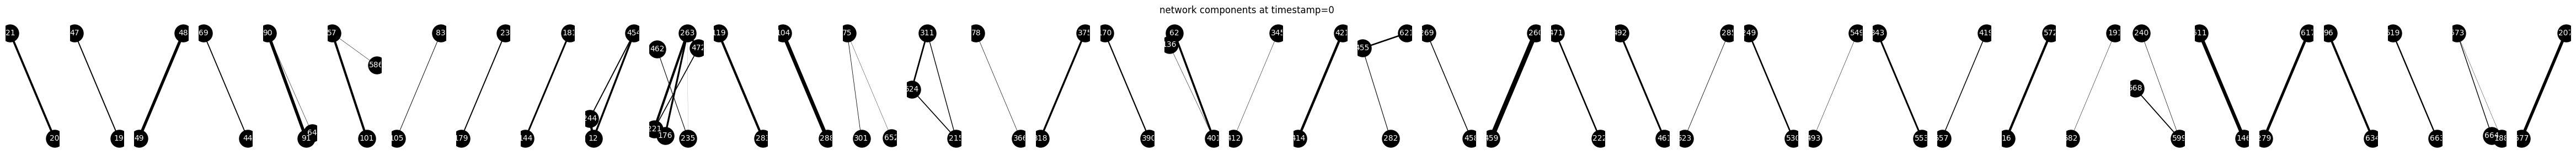

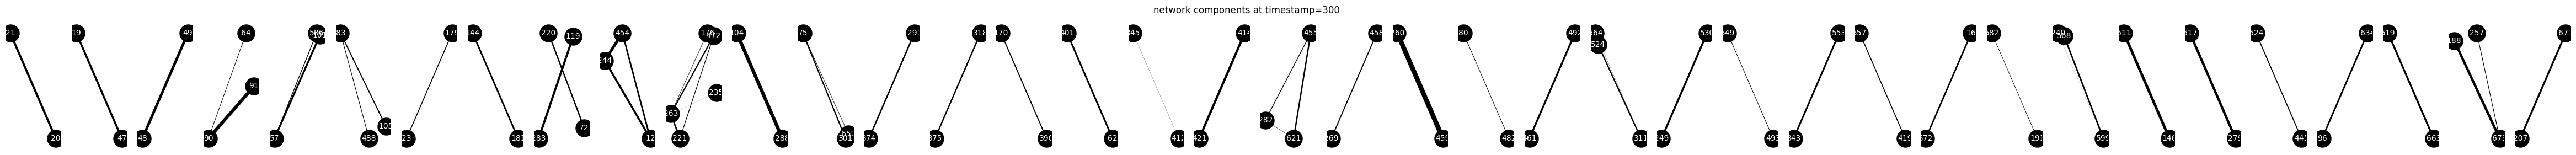

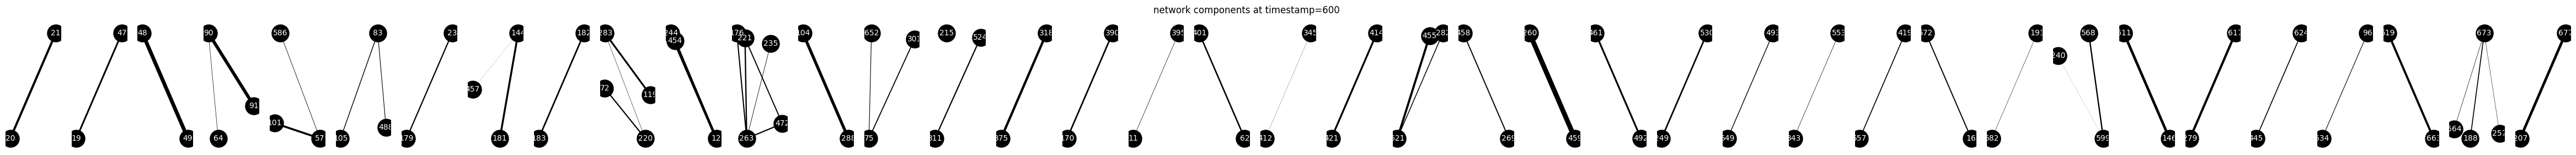

In [15]:
def VisualizeBluetoothNetwork(df_bt, timestamp):
  """ Plots each connected component in |df_bt| network at |timestamp|."""
  # NetworkX graph to plot the results.
  G = nx.Graph()

  # In-study users (id >= 0) at given timestamp.
  in_study_users_at_timestamp = df_bt[(df_bt["# timestamp"] == timestamp)
                                      & (df_bt["user_b"] >= 0)][[
                                          "user_a", "user_b", "rssi"
                                      ]]

  # Builds an undirected network of the in-study users.
  for row in in_study_users_at_timestamp.itertuples():
    user_a = row[1]
    user_b = row[2]
    rssi = row[3]
    G.add_edge(user_a, user_b, weight=rssi)

  # For clarity, we consier each connected component separately.
  # connected_components = list(nx.connected_component_subgraphs(G)) # Old, deprecated way
  connected_components = [G.subgraph(c).copy() for c in nx.connected_components(G)]
  # New way
  print("timestamp={}: {} participants, {} edges, {} connected components".format(
      timestamp, G.number_of_nodes(), G.number_of_edges(), len(connected_components)))
  # squeeze=False keeps axs 2-D even when there is only one component.
  fig, axs = plt.subplots(1, len(connected_components), figsize=(60, 3), squeeze=False)

  # Plots the connected components of the network.
  fig.suptitle("network components at timestamp={}".format(timestamp))
  [
      nx.draw(
          connected_component,
          # Positions of nodes are calculatued using spring layout.
          pos=nx.spring_layout(connected_component, scale=0.2),
          ax=axs[0][i],
          # Width of the edges is based on higher RSSI = stronger edge.
          width=[(100 + connected_component[u][v]["weight"]) / 10.0
                 for u, v in connected_component.edges()],
          node_size=500,
          node_color="black",
          with_labels=True,
          font_size=10,
          font_color="white")
      for i, connected_component in enumerate(connected_components)
  ]


VisualizeBluetoothNetwork(df_bt, 0)
VisualizeBluetoothNetwork(df_bt, 300)
VisualizeBluetoothNetwork(df_bt, 600)

## 5. Text messages by gender of sender and recipient

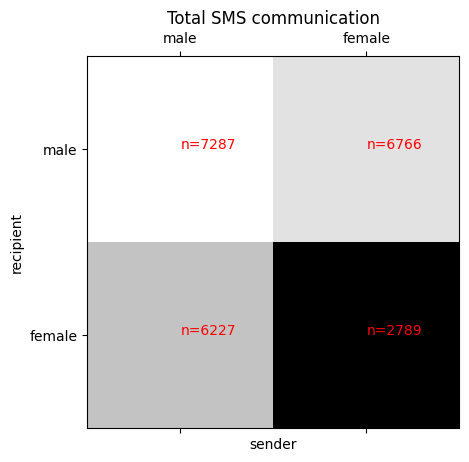

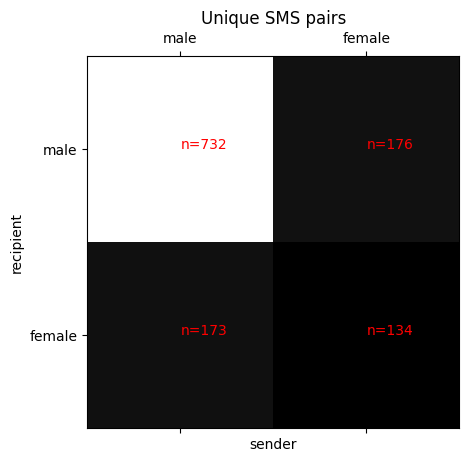

In [16]:
def VisualizeTextMessages(df_sms, df_genders):
  """Plots the SMS communication by gender of senders and recipients."""

  # Creates SMS network including gender of the senders.
  df_sms_with_gender_sender = pd.merge(
      df_sms, df_genders, left_on="sender", right_on="# user").rename(
          index=str, columns={
              "female": "female_sender"
          }).drop(
              "# user", axis=1)

  # Creates SMS network including gender of the recipients.
  df_sms_with_gender = pd.merge(
      df_sms_with_gender_sender,
      df_genders,
      left_on="recipient",
      right_on="# user").rename(
          index=str, columns={
              "female": "female_recipient"
          }).drop(
              "# user", axis=1)

  # Computes total communication (all messages) and number of unique pairs based
  # on sender and recipient gender.
  totals = np.zeros((2, 2))
  unique_pairs = np.zeros((2, 2))
  for female_sender in [0, 1]:
    for female_recipient in [0, 1]:
      totals[female_sender, female_recipient] = df_sms_with_gender[
          (df_sms_with_gender["female_sender"] == female_sender)
          &
          (df_sms_with_gender["female_recipient"] == female_recipient)].shape[0]
      unique_pairs[female_sender, female_recipient] = df_sms_with_gender[
          (df_sms_with_gender["female_sender"] == female_sender)
          & (df_sms_with_gender["female_recipient"] == female_recipient)][[
              "sender", "recipient"
          ]].drop_duplicates().shape[0]

  # Plots the breakdowns.
  # Transposed so that x = sender and y = recipient, matching the labels and counts.
  plt.matshow(totals.T, cmap=plt.cm.gray)
  plt.grid(False)
  plt.xlabel("sender")
  plt.ylabel("recipient")
  plt.xticks([0, 1], ["male", "female"])
  plt.yticks([0, 1], ["male", "female"])
  [
      plt.text(
          sender,
          recipient,
          "n={}".format(int(totals[sender][recipient])),
          color="red")
      for sender, recipient in itertools.product([0, 1], [0, 1])
  ]
  plt.title("Total SMS communication")

  plt.matshow(unique_pairs.T, cmap=plt.cm.gray)
  plt.grid(False)
  plt.xlabel("sender")
  plt.ylabel("recipient")
  plt.xticks([0, 1], ["male", "female"])
  plt.yticks([0, 1], ["male", "female"])
  [
      plt.text(
          sender,
          recipient,
          "n={}".format(int(unique_pairs[sender][recipient])),
          color="red")
      for sender, recipient in itertools.product([0, 1], [0, 1])
  ]
  plt.title("Unique SMS pairs")


VisualizeTextMessages(df_sms, df_genders)